# Coupled block graphs — defensive positioning tool

**Question:** in an organized block, does the defense cover the attack's passing graph, or only the ball?

Uses defense proximity graphs (`λ₂` of the combinatorial Laplacian), attack Delaunay danger, Hungarian marking, and supra-Laplacian coupling onto high-danger attack nodes. Sampling is 2 Hz inside `{low_block, medium_block, high_block}` only.

**Baselines this has to beat:** OOP width × length, nearest defender to the ball, and SkillCorner `overall_pressure`.

**Sample limit:** 20 matches. Phases are nested in matches, so naive CIs overstate precision.


In [1]:
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png')
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

import coupled_formation as cf
from coupled_formation import (
    DATA_DIR, OUT_DIR, load_match_meta, load_frame_geometry,
    possession_timeseries,
)

MATCH_ID = "1925299"  # Brisbane vs Perth — shots in low/medium block
PHASE_START, PHASE_END = 17583, 17981
FRAME = 17780

OUT_DIR.mkdir(parents=True, exist_ok=True)
meta = load_match_meta(DATA_DIR / MATCH_ID, MATCH_ID)
print(meta.home_name, "vs", meta.away_name, "| pitch", meta.pitch_length, "x", meta.pitch_width)
print("player_id field confirmed as match players[].id")

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100
mpl.rcParams['savefig.dpi'] = 100


Brisbane FC vs Perth Glory | pitch 105.0 x 68.0
player_id field confirmed as match players[].id


## Pitch snapshot — both graphs and Hungarian marking

Blue = defense proximity edges (weight > 0.05). Orange = attack Delaunay edges (width ∝ danger). Dotted = Hungarian assignment. Free attackers (assignment > 8 m or not goal-side) are highlighted in red.


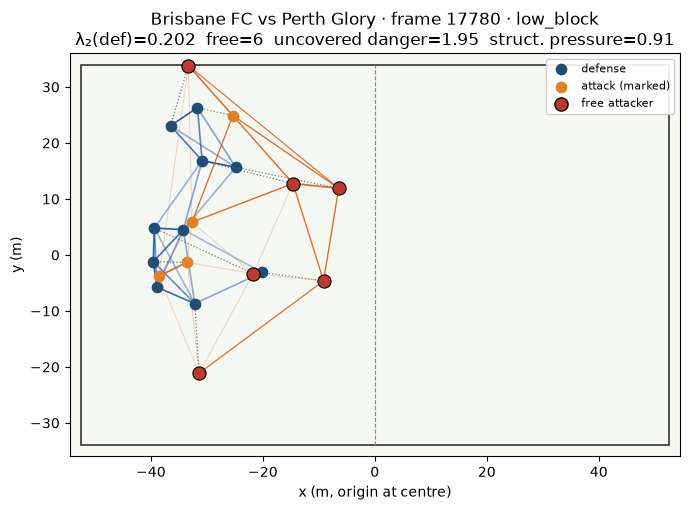

phase 17583 – 17981 | lead_to_shot True
attacking_side right_to_left | TIP Brisbane FC


In [2]:
row = load_frame_geometry(MATCH_ID, FRAME)
assert row is not None, f"no geometry at frame {FRAME}"
g = row["_geometry"]
def_xy, att_xy = g["_def_xy"], g["_att_xy"]
w_def, edges, dangers, occluded = g["_w_def"], g["_edges"], g["_dangers"], g["_occluded"]
marking = g["_marking"]
free = set(marking["free_idx"])
half_l, half_w = meta.pitch_length / 2, meta.pitch_width / 2

fig, ax = plt.subplots(figsize=(8, 5.2), dpi=100)
ax.set_facecolor("#f4f7f2")
ax.add_patch(plt.Rectangle((-half_l, -half_w), meta.pitch_length, meta.pitch_width,
                            fill=False, ec="#333", lw=1.2))
ax.plot([0, 0], [-half_w, half_w], color="#888", lw=0.8, ls="--")
segs, alphas = [], []
n = len(def_xy)
for i in range(n):
    for j in range(i + 1, n):
        if w_def[i, j] > 0.05:
            segs.append([def_xy[i], def_xy[j]])
            alphas.append(float(w_def[i, j]))
if segs:
    lc = LineCollection(segs, colors=[(0.15, 0.35, 0.7, min(1.0, 0.25 + a)) for a in alphas], linewidths=1.2)
    ax.add_collection(lc)
asegs, acols, alws = [], [], []
for k, (i, j) in enumerate(edges):
    asegs.append([att_xy[i], att_xy[j]])
    dng = float(dangers[k])
    alws.append(0.6 + 2.5 * dng)
    acols.append((0.85, 0.35, 0.05, 0.25 if occluded[k] else 0.85))
if asegs:
    ax.add_collection(LineCollection(asegs, colors=acols, linewidths=alws))
for p in marking["pairs"]:
    d, a = def_xy[p["def_idx"]], att_xy[p["att_idx"]]
    ax.plot([d[0], a[0]], [d[1], a[1]], color="#444", ls=":", lw=0.9, alpha=0.7)
ax.scatter(def_xy[:, 0], def_xy[:, 1], c="#1f4e79", s=55, zorder=5, label="defense")
for i, xy in enumerate(att_xy):
    if i in free:
        ax.scatter(xy[0], xy[1], c="#c0392b", s=90, zorder=6, edgecolors="k", linewidths=0.8)
    else:
        ax.scatter(xy[0], xy[1], c="#e67e22", s=55, zorder=5)
ax.scatter([], [], c="#e67e22", s=55, label="attack (marked)")
ax.scatter([], [], c="#c0392b", s=90, edgecolors="k", label="free attacker")
ax.set_xlim(-half_l - 2, half_l + 2)
ax.set_ylim(-half_w - 2, half_w + 2)
ax.set_aspect("equal")
title = (
    f"{meta.home_name} vs {meta.away_name} · frame {row['frame']} · {row['block_type']}\n"
    f"λ₂(def)={row['lambda2_defense']:.3f}  free={row['n_free_attackers']}  "
    f"uncovered danger={row['uncovered_danger']:.2f}  struct. pressure={row['structural_pressure']:.2f}"
)
ax.set_title(title)
ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
ax.set_xlabel("x (m, origin at centre)")
ax.set_ylabel("y (m)")
plt.tight_layout()
from IPython.display import display
display(fig)
plt.close(fig)
print("phase", row["frame_start"], "–", row["frame_end"], "| lead_to_shot", row["lead_to_shot"])
print("attacking_side", row["attacking_side"], "| TIP", row["team_in_possession"])


## Time series through one shot possession

Same Brisbane low-block phase (`frame_start=17583`). Watch `λ₂` (defense connectivity) and uncovered attack danger.


78 sampled frames in phase 17583–17981


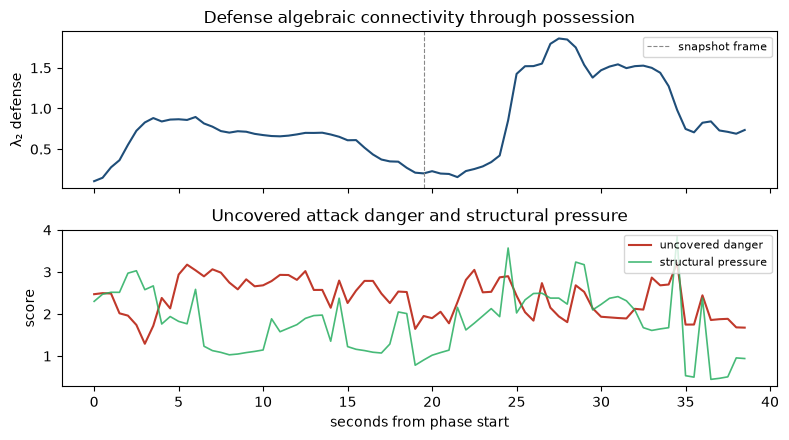

           frame  lambda2_defense  uncovered_danger  n_free_attackers  \
count     78.000           78.000            78.000            78.000   
mean   17777.500            0.816             2.383             5.628   
std      113.303            0.476             0.458             1.260   
min    17585.000            0.106             1.292             3.000   
25%    17681.250            0.455             1.945             5.000   
50%    17777.500            0.713             2.487             6.000   
75%    17873.750            0.961             2.786             6.000   
max    17970.000            1.861             3.216             8.000   

       structural_pressure  oop_width  nearest_defender_to_ball  
count               78.000     78.000                    78.000  
mean                 1.805     26.099                     5.038  
std                  0.744      2.929                     2.505  
min                  0.446     21.122                     0.385  
25%         

In [3]:
ts = possession_timeseries(MATCH_ID, PHASE_START, PHASE_END)
print(f"{len(ts)} sampled frames in phase {PHASE_START}–{PHASE_END}")
fig, axes = plt.subplots(2, 1, figsize=(8, 4.5), dpi=100, sharex=True)
t = (ts["frame"] - ts["frame"].iloc[0]) / 10.0
axes[0].plot(t, ts["lambda2_defense"], color="#1f4e79", lw=1.5)
axes[0].set_ylabel("λ₂ defense")
axes[0].set_title("Defense algebraic connectivity through possession")
axes[0].axvline((FRAME - ts["frame"].iloc[0]) / 10.0, color="#888", ls="--", lw=0.8, label="snapshot frame")
axes[0].legend(fontsize=8)
axes[1].plot(t, ts["uncovered_danger"], color="#c0392b", lw=1.5, label="uncovered danger")
axes[1].plot(t, ts["structural_pressure"], color="#27ae60", lw=1.2, alpha=0.85, label="structural pressure")
axes[1].set_ylabel("score")
axes[1].set_xlabel("seconds from phase start")
axes[1].legend(fontsize=8, loc="upper right")
axes[1].set_title("Uncovered attack danger and structural pressure")
plt.tight_layout()
from IPython.display import display
display(fig)
plt.close(fig)
print(ts[["frame", "lambda2_defense", "uncovered_danger", "n_free_attackers",
          "structural_pressure", "oop_width", "nearest_defender_to_ball"]].describe().round(3))


## Team summary across 20 matches

Defending-team means of graph metrics and shot rate against, from `analysis/output/team_summary.csv`.


In [4]:
teams = pd.read_csv(OUT_DIR / "team_summary.csv")
summary = json.load(open(OUT_DIR / "contrast_summary.json"))
display_cols = [
    "match_id", "defending_team", "n_phases", "shot_rate_against",
    "mean_lambda2_defense", "mean_uncovered_danger", "mean_n_free_attackers",
    "mean_structural_pressure", "mean_oop_area", "mean_nearest_defender_to_ball",
]
print(teams[display_cols].sort_values("shot_rate_against", ascending=False).head(12).to_string(index=False))
print()
print("Shot rates by block (graph-sampled phases):")
for b, v in summary["shot_rate_by_block"].items():
    print(f"  {b}: {v['shot_rate']:.1%} ({v['n_shot']}/{v['n_phases']})")
print()
print("Features whose residual (after width/length/nearest-defender/pressure + block) CI excludes 0:")
print(" ", summary["features_beating_baseline"] or "(none)")
print("Features that do NOT beat the box-and-pressure baseline:")
print(" ", summary["features_not_beating_baseline"])


 match_id  defending_team  n_phases  shot_rate_against  mean_lambda2_defense  mean_uncovered_danger  mean_n_free_attackers  mean_structural_pressure  mean_oop_area  mean_nearest_defender_to_ball
  1959846  Melbourne V FC       140           0.207143              0.251845               1.911864               5.657132                  1.626632    1800.556985                       6.092460
  1927964 Wellington P FC       150           0.200000              0.143010               2.290897               6.175012                  1.607887    2026.337577                       6.375202
  1996435 Adelaide United       164           0.195122              0.141615               2.037747               5.627453                  1.761177    1938.644499                       5.550999
  2011166 Wellington P FC       143           0.188811              0.200135               2.047245               5.193934                  1.983392    1750.696453                       5.478573
  1959846  Western United

## Note on baselines and the 20-match limit

- **Box baselines win the headline.** OOP width and width×length separate shot vs non-shot phases more cleanly than defense `λ₂`, free attackers, or uncovered danger once you residualize. In low block, mean OOP area is about 148 m² smaller in shot phases (bootstrap CI excludes 0).
- **Pressure is informative but collinear with the question.** `overall_pressure` AUC ≈ 0.57 for shots; that is on-ball pressure, not coverage of the rest of the graph.
- **One residual association:** `mean_lambda2_supra` retains a small residual difference after baselines (CI excludes 0), but primary structural-pressure and uncovered-danger features do **not**.
- **Pre-shot fracturing check:** overall, `λ₂` does **not** fall more in the last 2 s before shots than before sterile phases (diff shot−nons ≈ −0.022; if anything the opposite). By-block CIs include zero.
- **n = 20 matches.** Phases are nested in matches. Treat every CI as exploratory.
